In [9]:
from helpers import *

In [10]:
cmap_S = 'PuOr_r'
def get_state(snapshot_pattern, target_time, save_state=None,ax=0., az=0.):
    files = sorted(glob.glob(snapshot_pattern))
    if not files:
        raise FileNotFoundError(f"No files match pattern: {snapshot_pattern}")

    time_list = []
    u_list    = []
    te_list   = []
    sa_list = []

    x = z = None

    # --- loop over files ---
    for i, fname in enumerate(files):
        with h5py.File(fname, 'r') as f:
            # get coords only once
            if i == 0:
                x_key = next(k for k in f['scales'] if k.startswith('x_hash'))
                z_key = next(k for k in f['scales'] if k.startswith('z_hash'))
                x = np.squeeze(f[f'scales/{x_key}'][:])
                z = np.squeeze(f[f'scales/{z_key}'][:])

            # collect data
            time_list.append(f['scales/sim_time'][:])
            u_list.append(f['tasks/u'][:])
            te_list.append(f['tasks/te'][:])
            sa_list.append(f['tasks/sa'][:])

    # --- concatenate across files ---
    time = np.concatenate(time_list)
    u = np.concatenate(u_list)
    te = np.concatenate(te_list)
    sa = np.concatenate(sa_list)

    # --- find closest time ---
    idx = np.argmin(np.abs(time - target_time))
    print(f"Target time: {target_time}, selected: {time[idx]}")
    u_state  = u[idx]
    te_state = te[idx]
    sa_state = sa[idx]
    print(f"shape of u = {np.shape(u_state)}")
    u_state[0][:]=shift_field(u_state[0][:], ax, az)
    u_state[1][:]=shift_field(u_state[1][:], ax, az)
    te_state=shift_field(te_state, ax, az)
    sa_state=shift_field(sa_state, ax, az)

    # --- optionally save state ---
    if save_state is not None:
        os.makedirs(os.path.dirname(save_state), exist_ok=True)
        with nc.Dataset(save_state, 'w') as ds:
            # dimensions
            ds.createDimension('x',    len(x))
            ds.createDimension('z',    len(z))
            ds.createDimension('time', 1)

            # coordinates
            ds.createVariable('time', 'f8', ('time',))[:] = time[idx]
            ds.createVariable('x',    'f8', ('x',))[:] = x
            ds.createVariable('z',    'f8', ('z',))[:] = z

            # fields
            ds.createVariable('u_0', 'f8', ('z', 'x'))[:] = np.reshape(u_state[0].T, (len(z), len(x)))
            ds.createVariable('u_1', 'f8', ('z', 'x'))[:] = np.reshape(u_state[1].T, (len(z), len(x)))
            ds.createVariable('te',  'f8', ('z', 'x'))[:] = np.reshape(te_state.T, (len(z), len(x)))
            ds.createVariable('sa',  'f8', ('z', 'x'))[:] = np.reshape(sa_state.T, (len(z), len(x)))
        print(f"State saved to: {save_state}")
    
    return x, z, sa_state

def shift_field(sa, ax, az):
    Nz = sa.shape[0]
    Nx = sa.shape[1]
    shift_x = int(round(ax * Nx))
    shift_z = int(round(az * Nz))
    shift_sa = np.roll(sa, shift=(shift_x, shift_z), axis=(0, 1))
    return shift_sa

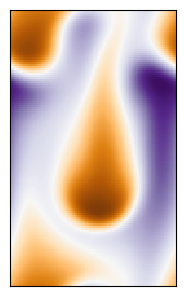

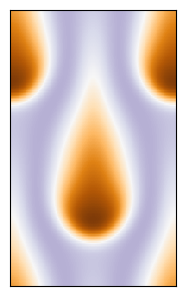

In [11]:
# [x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshots/snapshots_s*.h5',
#                      target_time=273.8,
#                      save_state='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_TM1.nc',
#                      ax=-0.18, az=0.3)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_TM1.nc',
            name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_TM1.png',plot_mean_profiles=False,symmetric=True)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TM1/solution.nc',plot_mean_profiles=False,symmetric=True)


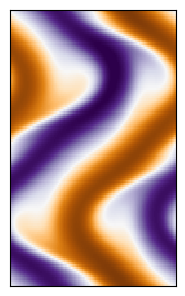

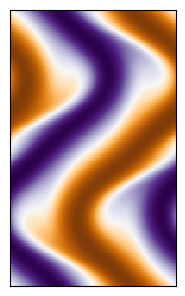

In [12]:
# [x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshots/snapshots_s*.h5',
#                      target_time=89.1,
#                      save_state='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_WF.nc',
#                      ax= -0.35,az= 0.11)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_WF.nc',
            name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_WF.png',plot_mean_profiles=False,symmetric=True)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_WF/solution.nc',plot_mean_profiles=False,symmetric=True)

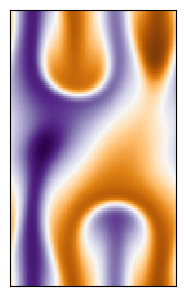

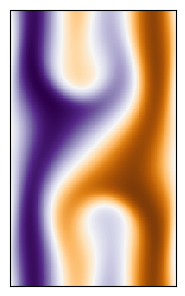

In [13]:
# [x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshots/snapshots_s*.h5',
#                      target_time=135.7,
#                      save_state='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_H.nc',
#                      ax= -0.2,az= -0.08)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_H.nc',
            name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_H.png',plot_mean_profiles=False,symmetric=True)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_H/solution.nc',plot_mean_profiles=False,symmetric=True)

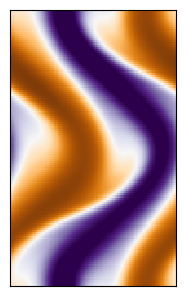

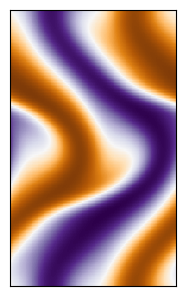

In [14]:
# [x,z,sa] = get_state(snapshot_pattern='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshots/snapshots_s*.h5',
#                      target_time=114.3,
#                      save_state='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_TWF.nc',
#                      ax= -0.2,az= -0.12)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_TWF.nc',
            name='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshot_TWF.png',plot_mean_profiles=False,symmetric=True)
plot_sample(path='Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TWF/solution.nc',plot_mean_profiles=False,symmetric=True)
